Import libraries and functions

In [19]:
import json
import time
from poisson_bcann_vi import *
from codebase_0 import (
    set_seed, DeviceLoader, poisson_deviance
)
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
from torch import nn
import pyro
from sklearn.preprocessing import MinMaxScaler


seed = 42
set_seed(seed)
pyro.clear_param_store()


Load data and perform train/validation/test split

In [ ]:
device = torch.device("cuda")

torch.set_default_device("cpu")


dataset = pd.read_csv("freMTPL2freq_transformed.csv", index_col= 0) 
y = torch.tensor(dataset["ClaimNb"].to_numpy(), dtype=torch.float32)
exposure = torch.tensor(dataset["Exposure"].to_numpy(), dtype=torch.float32)
X = torch.tensor(dataset.drop(columns=["IDpol", "Exposure","ClaimNb"]).to_numpy(), dtype=torch.float32)   # 48 columns

# Learning-test set split
X_learn, X_test, y_learn, y_test, exp_learn, exp_test = train_test_split(
    X, y, exposure, test_size= 0.1, random_state= seed
)

# Training-CV set split
X_train, X_val, y_train, y_val, exp_train, exp_val = train_test_split(
    X_learn, y_learn, exp_learn, test_size= 0.1, random_state= seed
)

learn_scaler = MinMaxScaler().fit(X_learn)
X_learn = learn_scaler.transform(X_learn)
X_test = learn_scaler.transform(X_test)

train_scaler = MinMaxScaler().fit(X_train)
X_train = train_scaler.transform(X_train)
X_val = train_scaler.transform(X_val)

def T(a):
    return torch.as_tensor(a, dtype=torch.float32, device=device)

X_train, X_val, X_learn, X_test = map(T, (X_train, X_val, X_learn, X_test))
y_train, y_val, y_learn, y_test = map(T, (y_train, y_val, y_learn, y_test))
exp_train, exp_val, exp_learn, exp_test = map(T, (exp_train, exp_val, exp_learn, exp_test))

torch.set_default_device(device)
train_loader = DeviceLoader(
        X_train, y_train, torch.log(exp_train),
        batch_size = 10000,
        shuffle= True
)
val_loader = DeviceLoader(
        X_val, y_val, torch.log(exp_val),
        batch_size= 10000
        
)
learn_loader = DeviceLoader(
        X_learn, y_learn, torch.log(exp_learn),
        batch_size= 10000
)
test_loader = DeviceLoader(
        X_test, y_test, torch.log(exp_test),
        batch_size= 10000
)

Poisson GLM/MLE fitting

In [8]:
time_0 = time.time()
glm_mle = poisson_fit_glm_mle(X_train, y_train, log_exposure= torch.log(exp_train), random_state=seed)
with torch.no_grad():
    glm_val_dev = poisson_deviance(y_true=y_val, y_pred=X_val @ glm_mle[0].T.squeeze(-1) + glm_mle[1]).item()
    print(f"GLM (MLE) val deviance: {glm_val_dev:.4f}")
time_1 = time.time()
print(time_1 - time_0)

GLM (MLE) val deviance: 0.3590
5.741556882858276


In [15]:
with torch.no_grad():
    glm_val_dev = poisson_deviance(y_true=y_train, y_pred=X_train @ glm_mle[0].T.squeeze(-1) + glm_mle[1]).item()
    print(f"GLM (MLE) train deviance: {glm_val_dev:.4f}")

GLM (MLE) train deviance: 0.3585


# CANN

Start a CANN model

In [16]:
network_architecture = [20, 15, 10]
poisson_cann= PoissonCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= 42
).to(device)


Training CANN

In [5]:
cann_history = poisson_cann_training_loop(
    cann_model= poisson_cann,
    glm_loss_function= nn.PoissonNLLLoss(log_input= True),
    nn_loss_function= poisson_deviance,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 300,
    train_loader= train_loader,
    val_loader= val_loader,
    random_state= 42,
    device= device
)

Epoch 1 | train loss: 0.3146 | val loss: 0.3198
Epoch 25 | train loss: 0.3101 | val loss: 0.3148
Epoch 50 | train loss: 0.3062 | val loss: 0.3131
Epoch 75 | train loss: 0.3048 | val loss: 0.3124
Early stopping at epoch 95. Best val loss 0.3124 at epoch 75


Traing CANN with best epoch

In [17]:
time_0 = time.time()
cann_history = poisson_cann_training_loop(
    cann_model= poisson_cann,
    glm_loss_function= nn.PoissonNLLLoss(log_input= True),
    nn_loss_function= poisson_deviance,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 75,
    train_loader= train_loader,
    val_loader= val_loader,
    random_state= 42,
    device= device,
    early_stop_params={"patience": 76} # full 75 epochs
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | train loss: 0.3146 | val loss: 0.3198
Epoch 25 | train loss: 0.3101 | val loss: 0.3148
Epoch 50 | train loss: 0.3062 | val loss: 0.3131
Epoch 75 | train loss: 0.3048 | val loss: 0.3124
11.713308811187744


# BCANN

Start a PoissonBCANN model

In [9]:
pyro.clear_param_store()

bcann_gaussian_prior = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
guide = build_bcann_guide(bcann_gaussian_prior, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)

Train PoissonBCANN with early stopping

In [10]:
time_0 = time.time()
bcann_history = poisson_bcann_svi_training_loop(
        bcann_gaussian_prior, guide, train_loader, val_loader,
        n_epochs=300, lr=5e-3, val_every=10, patience=5, random_state=seed, device = device)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | -ELBO/n: 0.2143 | train deviance: 0.3146 | val deviance: 0.3199
Epoch 50 | -ELBO/n: 0.2114 | train deviance: 0.3147 | val deviance: 0.3198
Early stopping at epoch 70. Best val deviance 0.3198 at epoch 20
452.18354177474976


Train PoissonBCANN to best epoch

In [12]:
pyro.clear_param_store()

poisson_bcann = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
glm_mle = poisson_fit_glm_mle(X_train, y_train, log_exposure= torch.log(exp_train), random_state=seed)
guide = build_bcann_guide(poisson_bcann, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)
time_0 = time.time()
bcann_history_best_ep = poisson_bcann_svi_training_loop(
    poisson_bcann, guide, train_loader, val_loader,
    n_epochs=20, lr=5e-3, val_every=21, patience=301, # to ensure all 9 epochs run with no cross validation
    random_state=seed, device = device
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | -ELBO/n: 0.2143 | train deviance: 0.3146 | val deviance: 0.3199
72.59540820121765


In [13]:
print(bcann_history_best_ep["best_val_deviance"])
print(bcann_history_best_ep["train_deviance"][-1])

0.3198847472667694
0.31464672088623047


# Train on learn set and get performance on test set

In [15]:
pyro.clear_param_store()

best_poisson_bcann = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
glm_mle = poisson_fit_glm_mle(X_train, y_train, log_exposure= torch.log(exp_train), random_state=seed)
guide = build_bcann_guide(best_poisson_bcann, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)
time_0 = time.time()
bcann_history_best_ep = poisson_bcann_svi_training_loop(
    best_poisson_bcann, guide, learn_loader, val_loader,
    n_epochs=20, lr=5e-3, val_every=21, patience=301, # to ensure all 9 epochs run with no cross validation
    random_state=seed, device = device
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | -ELBO/n: 0.2132 | train deviance: 0.3154 | val deviance: 0.3201
100.62909579277039


In [22]:
# write to disk 

torch.save({
    "recipe": {
        "cls": "PoissonBCANN",
        "kwargs": dict(in_features= 48,
            neural_net_params={"hidden_activation_nodes": network_architecture,
                                "hidden_activations": nn.Tanh,
                                "prior_scale": 1}),
    },
    "guide_builder": "build_bcann_guide",
    "guide_kwargs": dict(rank=10),                     # + tau_init for the horseshoe builders
    "guide_state": {k: v.detach().cpu() for k, v in guide.state_dict().items()},
}, "runs/poisson_bcann_vi.pt")

In [ ]:
# Poisson BCANN with Gaussian prior deviance on test set
evaluate_bcann(best_poisson_bcann, guide, test_loader, 200, device = device)

0.3089936375617981

In [ ]:
network_architecture = [20, 15, 10]
best_poisson_cann= PoissonCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= 42
).to(device)
time_0 = time.time()
cann_history = poisson_cann_training_loop(
    cann_model= best_poisson_cann,
    glm_loss_function= nn.PoissonNLLLoss(log_input= True),
    nn_loss_function= poisson_deviance,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 75,
    train_loader= learn_loader,
    val_loader= val_loader, # passed in but do not use as patience is 76 -> so printed val_loss is not reliable
    random_state= 42,
    device= device,
    early_stop_params={"patience": 76} # full 75 epochs
)
time_1 = time.time()
print(time_1 - time_0)

Epoch 1 | train loss: 0.3151 | val loss: 0.3196
Epoch 25 | train loss: 0.3073 | val loss: 0.3112
Epoch 50 | train loss: 0.3057 | val loss: 0.3100
Epoch 75 | train loss: 0.3049 | val loss: 0.3095
12.237754344940186


In [ ]:
# CANN deviance on test set
poisson_deviance(y_true = y_test, y_pred = best_poisson_cann(X_test, torch.log(exp_test)))

tensor(0.3045, device='cuda:0', grad_fn=<MulBackward0>)

In [ ]:
# GLM deviance on test set
poisson_learn_glm_mle = poisson_fit_glm_mle(X_learn, y_learn, log_exposure= torch.log(exp_learn), random_state=seed)
with torch.no_grad():
    glm_val_dev = poisson_deviance(y_true=y_test, y_pred=X_test @ poisson_learn_glm_mle[0].T.squeeze(-1) + poisson_learn_glm_mle[1]).item()
    print(f"GLM (MLE) test deviance: {glm_val_dev:.4f}")

GLM (MLE) test deviance: 0.3539


# Full 300 epoch run + Graphing

CANN full 300 epoch run

In [5]:
network_architecture = [20, 15, 10]
poisson_cann= PoissonCANN(
    in_features= 48, 
    neural_net_params= {"hidden_activation_nodes": network_architecture},
    random_state= 42
).to(device)

cann_history = poisson_cann_training_loop(
    cann_model= poisson_cann,
    glm_loss_function= nn.PoissonNLLLoss(log_input= True),
    nn_loss_function= poisson_deviance,
    nn_optimiser= torch.optim.Adam,
    nn_optim_params = {"lr": 5e-3},
    nn_epochs= 300,
    train_loader= train_loader,
    val_loader= val_loader,
    random_state= 42,
    device= device,
    early_stop_params= {"patience": 301} # ensure the entire 300 epochs run
)

Epoch 1 | train loss: 0.3146 | val loss: 0.3198
Epoch 25 | train loss: 0.3101 | val loss: 0.3148
Epoch 50 | train loss: 0.3062 | val loss: 0.3131
Epoch 75 | train loss: 0.3048 | val loss: 0.3124
Epoch 100 | train loss: 0.3040 | val loss: 0.3132
Epoch 125 | train loss: 0.3034 | val loss: 0.3138
Epoch 150 | train loss: 0.3029 | val loss: 0.3151
Epoch 175 | train loss: 0.3022 | val loss: 0.3155
Epoch 200 | train loss: 0.3017 | val loss: 0.3154
Epoch 225 | train loss: 0.3012 | val loss: 0.3159
Epoch 250 | train loss: 0.3007 | val loss: 0.3159
Epoch 275 | train loss: 0.3002 | val loss: 0.3169
Epoch 300 | train loss: 0.2998 | val loss: 0.3179


BCANN with Gaussian prior 300 epoch run

In [ ]:
pyro.clear_param_store()

poisson_bcann = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1},
).to(device)
guide = build_bcann_guide(poisson_bcann, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=10)
bcann_history = poisson_bcann_svi_training_loop(
    poisson_bcann, guide, train_loader, val_loader,
    n_epochs=300, lr=5e-3, val_every=1, patience=301, # to ensure all 300 epochs run
    random_state=seed, device = device
)

# write to disk as it is computationally expensive to rerun

# import json

# with open("plotting_json/poisson_bcann.json", "w") as f:
#     json.dump(bcann_history, f, indent=2)

Epoch 1 | -ELBO/n: 0.2147 | train deviance: 0.3147 | val deviance: 0.3199
Epoch 25 | -ELBO/n: 0.2112 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 50 | -ELBO/n: 0.2109 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 75 | -ELBO/n: 0.2112 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 100 | -ELBO/n: 0.2126 | train deviance: 0.3146 | val deviance: 0.3199
Epoch 125 | -ELBO/n: 0.2115 | train deviance: 0.3146 | val deviance: 0.3199
Epoch 150 | -ELBO/n: 0.2114 | train deviance: 0.3147 | val deviance: 0.3199
Epoch 175 | -ELBO/n: 0.2108 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 200 | -ELBO/n: 0.2109 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 225 | -ELBO/n: 0.2112 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 250 | -ELBO/n: 0.2112 | train deviance: 0.3146 | val deviance: 0.3199
Epoch 275 | -ELBO/n: 0.2113 | train deviance: 0.3146 | val deviance: 0.3198
Epoch 300 | -ELBO/n: 0.2112 | train deviance: 0.3146 | val deviance: 0.3198


In [7]:
with open("plotting_json/poisson_bcann.json") as f:
    poisson_bcann_history_full = json.load(f) # bcann with horseshoe prior 

BCANN wth regularised horseshoe prior (trained in poisson_bcann_horseshoe.ipynb) 300 epoch run

In [8]:
with open("plotting_json/poisson_horseshoe_bcann.json") as f:
    poisson_horseshoe_history_full = json.load(f) # bcann with horseshoe prior 

Graphing

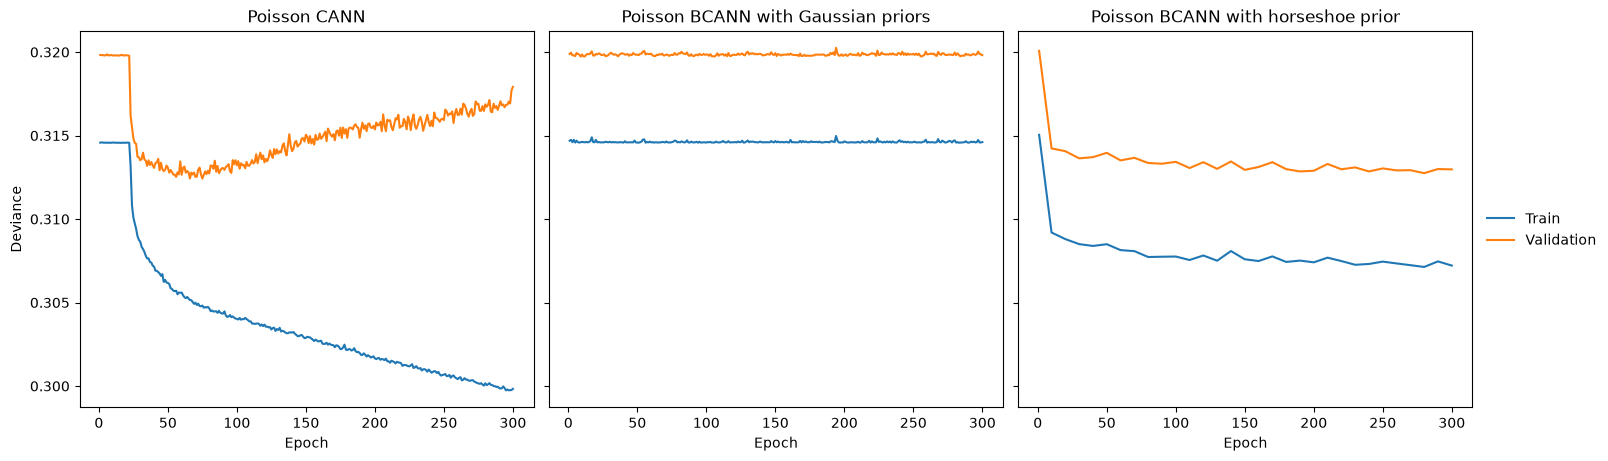

In [17]:
import matplotlib.pyplot as plt

# CANN: logged every epoch
c_tr = np.asarray(cann_history["train_losses"])
c_val = np.asarray(cann_history["val_losses"])
c_x_tr = np.arange(1, len(c_tr) + 1)
c_x_val = np.arange(1, len(c_val) + 1)

# BCANN (Poisson): x-axis from val_epochs
b = poisson_bcann_history_full
b_x_val = np.asarray(b["val_epochs"])
b_val = np.asarray(b["val_deviance"])
b_tr = np.asarray(b["train_deviance"])
b_x_tr = b_x_val if len(b_tr) == len(b_x_val) else np.arange(1, len(b_tr) + 1)

# Horseshoe BCANN (Poisson): recorded every 10 epochs, x-axis from val_epochs
hs = poisson_horseshoe_history_full
hs_x_val = np.asarray(hs["val_epochs"])
hs_val = np.asarray(hs["val_deviance"])
hs_tr = np.asarray(hs["train_deviance"])
hs_x_tr = hs_x_val if len(hs_tr) == len(hs_x_val) else np.arange(10, 10 * len(hs_tr) + 1, 10)

panels = [
    ("Poisson CANN", c_x_tr, c_tr, c_x_val, c_val),
    ("Poisson BCANN with Gaussian priors", b_x_tr, b_tr, b_x_val, b_val),
    ("Poisson BCANN with horseshoe prior", hs_x_tr, hs_tr, hs_x_val, hs_val),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, sharex=True,
                         layout="constrained")

for ax, (name, x_tr, tr, x_val, val) in zip(axes, panels):
    ax.plot(x_tr, tr, color="tab:blue", label="Train")
    ax.plot(x_val, val, color="tab:orange", label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")

axes[0].set_ylabel("Deviance")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside center right", frameon=False)

plt.show()

# fig.savefig("poisson_deviance_curves.pdf", bbox_inches="tight")

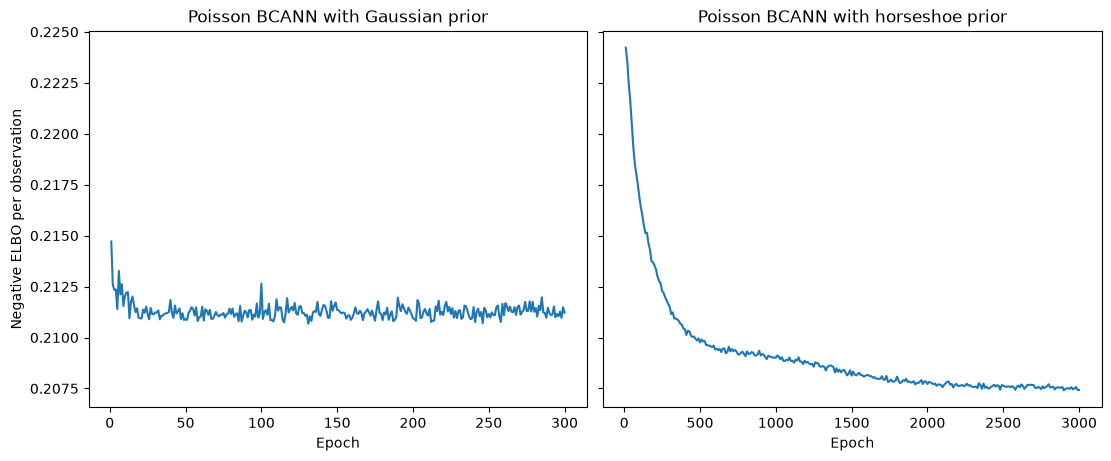

In [16]:
# BCANN
b = np.asarray(poisson_bcann_history_full["neg_elbo_per_obs"])
b_x = np.arange(1, len(b) + 1)
# BCANN Horseshoe
hs = np.asarray(poisson_horseshoe_history_full["neg_elbo_per_obs"])
hs_x = np.arange(10, 10 * len(hs) + 1, 10)

panels = [
    ("Poisson BCANN with Gaussian prior", b_x, b),
    ("Poisson BCANN with horseshoe prior", hs_x, hs),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True, sharex=False,
                         layout="constrained")

for ax, (name, x, y) in zip(axes, panels):
    ax.plot(x, y, color="tab:blue")
    ax.set_title(name)
    ax.set_xlabel("Epoch")

axes[0].set_ylabel("Negative ELBO per observation")

plt.show()

# fig.savefig("poisson_neg_elbo_curves.pdf", bbox_inches="tight")

## Sensitivity test

In [ ]:
# sensitivity of prediction performance on value of sigma^2_w
sigma_sensi_scores = []
for sigma_sqrt in np.linspace(0.5, 2, 4):
    pyro.clear_param_store()
    
    set_seed(seed)
    model = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": sigma_sqrt}).to(device)
    guide = build_bcann_guide(model, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=20)
    bcann_history = poisson_bcann_svi_training_loop(
        model, guide, train_loader, val_loader,
        n_epochs=300, lr=5e-3, val_every=5, patience=10, random_state=seed, device = device, kl_scheme= "uniform")
    sigma_sensi_scores.append({"sigma": sigma_sqrt, **bcann_history})

Epoch 1 | -ELBO/n: 0.2254 | train deviance: 0.3146 | val deviance: 0.3199


In [ ]:
# sensitivity of prediction performance on value of sigma^2_w
kl_sensi_scores = []
for kl in ["blundell", "uniform"]:
    pyro.clear_param_store()
    
    set_seed(seed)
    model = PoissonBCANN(
    in_features= 48,
    neural_net_params={"hidden_activation_nodes": network_architecture,
                        "hidden_activations": nn.Tanh,
                        "prior_scale": 1}).to(device)
    guide = build_bcann_guide(model, X_train[:256], y_train[:256], glm_mle=glm_mle, rank=20)
    bcann_history = poisson_bcann_svi_training_loop(
        model, guide, train_loader, val_loader,
        n_epochs=300, lr=5e-3, val_every=5, patience=10, random_state=seed, device = device, kl_scheme= kl)
    kl_sensi_scores.append({"kl": kl, **bcann_history})

Epoch 1 | -ELBO/n: 11224.8729 | val deviance: 300.9985
Epoch 25 | -ELBO/n: 0.2129 | val deviance: 0.3207
Epoch 50 | -ELBO/n: 0.2130 | val deviance: 0.3220
Epoch 75 | -ELBO/n: 0.2116 | val deviance: 0.3201
Epoch 100 | -ELBO/n: 0.2119 | val deviance: 0.3205
Epoch 125 | -ELBO/n: 0.2119 | val deviance: 0.3216
Early stopping at epoch 145. Best val deviance 0.3198 at epoch 95
Epoch 1 | -ELBO/n: 11240.2309 | val deviance: 294.5081
Epoch 25 | -ELBO/n: 0.2111 | val deviance: 0.3218
Epoch 50 | -ELBO/n: 0.2103 | val deviance: 0.3201
Epoch 75 | -ELBO/n: 0.2095 | val deviance: 0.3206
Epoch 100 | -ELBO/n: 0.2095 | val deviance: 0.3203
Epoch 125 | -ELBO/n: 0.2098 | val deviance: 0.3204
Early stopping at epoch 135. Best val deviance 0.3198 at epoch 85
